**CS 4140 – Deep Learning · L10 · Training deeper networks** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L10_deeper-networks/L10_training_deeper_networks.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L10_deeper-networks"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 10 · Training Deeper Networks

**Residual connections, initialization and batch normalization: the saved runs behind the slides.**

| Part | Question | Slide |
|---|---|---|
| 1 | Why do gradients vanish or explode? (a product of many factors) | "Why Do Gradients Vanish or Explode?" |
| 2 | What does a good initialization buy us? | "Tool 1: Initialization" |
| 3 | How does the gradient flow through 56 layers at the start of training? | "A Highway for the Gradient" |
| 4 | Is a deeper plain network better? Is a deeper residual network better? | "We Tried It", "Plain vs Residual" |
| 5 | What do initialization and batch normalization change in training? | "Batch Normalization" |
| 6 | What happens if we delete one block from a trained network? | "Remove One Block" |
| 7 | What is inside a pretrained ResNet-18? | "Inspecting a Pretrained ResNet-18" |

**Two ways to run it**

* `CLASS_MODE = True` (default): loads the saved training runs from `results/` and redraws every figure; only a run that is missing gets trained. The cheap probes (Parts 1–3) run live. About 20–30 seconds on a laptop.
* `CLASS_MODE = False`: retrains all seven small CNNs on Fashion-MNIST. About 20–25 minutes on a 2-core CPU, much less on a GPU. Each run is saved when it finishes, so an interrupted run can be completed in class mode.

The first run downloads Fashion-MNIST (about 30 MB) and, for Part 7, the ResNet-18 weights (about 45 MB). Without internet, Part 7 falls back to the saved predictions.

In [1]:
CLASS_MODE = True          # False = retrain everything (about 20 min on a 2-core CPU)

import os, gzip, json, math, time, types, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager

torch.set_num_threads(max(1, os.cpu_count() or 1))
DATA, RESULTS, FIGS = 'data', 'results', 'figures'
LAYERS = os.path.join(FIGS, 'layers')
for d in (DATA, RESULTS, FIGS, LAYERS):
    os.makedirs(d, exist_ok=True)

# Figures use a Century Schoolbook look when the font is available (TeX Gyre Schola is a free clone)
for f in font_manager.findSystemFonts():
    if 'schola' in f.lower() or 'century schoolbook' in f.lower() or 'centsch' in f.lower():
        font_manager.fontManager.addfont(f)
names = {f.name for f in font_manager.fontManager.ttflist}
SERIF = next((n for n in ['Century Schoolbook', 'TeX Gyre Schola', 'DejaVu Serif'] if n in names), 'serif')
plt.rcParams.update({'font.family': SERIF, 'font.size': 15, 'axes.titlesize': 17, 'axes.labelsize': 16,
                     'legend.fontsize': 14, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 110, 'savefig.dpi': 200, 'mathtext.fontset': 'dejavuserif'})
BLUE, RED, GREY, NAVY, GREEN = '#1A1AFF', '#C00000', '#8C8C8C', '#000080', '#2E8B57'

def save(fig, name):
    fig.savefig(os.path.join(FIGS, name + '.png'), bbox_inches='tight', facecolor='white')

def save_layers(fig, name, groups, hide=None):
    """One full image per click (same size, so they stack exactly on a slide).
    groups[k] = artists that appear at click k; hide[k] = artists that disappear at click k."""
    hide = hide or {}
    fig.canvas.draw()                                        # one tight box for all layers (everything visible)
    box = fig.get_tightbbox(fig.canvas.get_renderer()).padded(0.08)
    for g in groups:
        for a in g: a.set_visible(False)
    for k, g in enumerate(groups, 1):
        for a in g: a.set_visible(True)
        for a in hide.get(k, []): a.set_visible(False)
        fig.savefig(os.path.join(LAYERS, f'{name}_{k}.png'), facecolor='white', bbox_inches=box)
    fig.savefig(os.path.join(FIGS, name + '.png'), facecolor='white', bbox_inches=box)

# ---------------------------------------------------------------- data
URL = 'http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/'
FILES = ['train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz',
         't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz']
for f in FILES:
    if not os.path.exists(os.path.join(DATA, f)):
        print('downloading', f); urllib.request.urlretrieve(URL + f, os.path.join(DATA, f))

def read_idx(f, offset):
    with gzip.open(os.path.join(DATA, f)) as h:
        return np.frombuffer(h.read(), np.uint8, offset=offset)
Xall = read_idx(FILES[0], 16).reshape(-1, 1, 28, 28); yall = read_idx(FILES[1], 8)

def to_tensor(X, y):
    X = torch.tensor(X, dtype=torch.float32) / 255.0
    return (X - 0.2860) / 0.3530, torch.tensor(y, dtype=torch.long)

# fixed split of the official training set: 12,000 images to train, 2,000 to validate
order = np.random.default_rng(0).permutation(len(Xall))
Xtr, ytr = to_tensor(Xall[order[:12000]], yall[order[:12000]])
Xva, yva = to_tensor(Xall[order[50000:52000]], yall[order[50000:52000]])
print('train', tuple(Xtr.shape), ' validation', tuple(Xva.shape))

train (12000, 1, 28, 28)  validation (2000, 1, 28, 28)


In [2]:
# ---------------------------------------------------------------- the two kinds of block
class Block(nn.Module):
    """Two 3x3 convolutions. residual=True adds the skip connection (a ResNet 'basic block')."""
    def __init__(self, cin, cout, stride=1, residual=True, bn=True):
        super().__init__()
        self.residual = residual
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=not bn)
        self.bn1 = nn.BatchNorm2d(cout) if bn else nn.Identity()
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=not bn)
        self.bn2 = nn.BatchNorm2d(cout) if bn else nn.Identity()
        self.shortcut = nn.Identity()
        if residual and (stride != 1 or cin != cout):
            # the shape changes, so the shortcut needs a 1x1 convolution (as in torchvision's ResNet)
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=not bn),
                                          nn.BatchNorm2d(cout) if bn else nn.Identity())
        self.removed = False                       # used in Part 6

    def forward(self, x):
        if self.removed:                           # Part 6: delete the block (keep only the shortcut)
            return F.relu(self.shortcut(x)) if self.residual else x
        out = F.relu(self.bn1(self.conv1(x)))      # a[l+1] = g(z[l+1])
        out = self.bn2(self.conv2(out))            # z[l+2]
        if self.residual:
            out = out + self.shortcut(x)           # z[l+2] + a[l]   <- the skip connection
        return F.relu(out)                         # a[l+2]

class Net(nn.Module):
    """CIFAR-style network for 28x28 images: 1 conv + 3 stages of n blocks + 1 linear = 6n + 2 layers."""
    def __init__(self, n=3, width=8, residual=True, bn=True, init='he'):
        super().__init__()
        self.depth = 6 * n + 2
        self.stem = nn.Sequential(nn.Conv2d(1, width, 3, 1, 1, bias=not bn),
                                  nn.BatchNorm2d(width) if bn else nn.Identity(), nn.ReLU())
        blocks, cin = [], width
        for stage, cout in enumerate([width, 2 * width, 4 * width]):     # 28x28, 14x14, 7x7
            for i in range(n):
                blocks.append(Block(cin, cout, 2 if (stage > 0 and i == 0) else 1, residual, bn))
                cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(cin, 10)
        if init == 'he':                           # He initialization: Var(w) = 2 / n_in
            for m in self.modules():
                if isinstance(m, nn.Conv2d):
                    nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                    if m.bias is not None: nn.init.zeros_(m.bias)
        # init == 'default' keeps PyTorch's built-in initialization

    def forward(self, x):
        return self.fc(F.adaptive_avg_pool2d(self.blocks(self.stem(x)), 1).flatten(1))

def n_params(m): return sum(p.numel() for p in m.parameters())
for n in (3, 9):
    print(f'{6*n+2} layers: plain {n_params(Net(n, residual=False)):,} parameters, '
          f'residual {n_params(Net(n, residual=True)):,}')

20 layers: plain 67,906 parameters, residual 68,642
56 layers: plain 214,402 parameters, residual 215,138


In [3]:
# ---------------------------------------------------------------- training (the loop from Jan 20 + Jan 27)
@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval()                                   # batch norm uses its running averages
    loss = correct = 0.0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss += F.cross_entropy(out, y[i:i + bs], reduction='sum').item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss / len(X), correct / len(X)

def train(model, epochs=10, lr=0.1, bs=128, seed=0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)
    steps = epochs * math.ceil(len(Xtr) / bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.15)
    h = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc']}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=g)
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        trl, tra = evaluate(model, Xtr[:4000], ytr[:4000])     # training error on 4,000 training images
        val, vaa = evaluate(model, Xva, yva)
        for k, v in zip(h, [trl, tra, val, vaa]): h[k].append(v)
        print(f'  epoch {ep:2d}  train loss {trl:.3f}  train acc {tra:.1%}  val acc {vaa:.1%}  ({time.time()-t0:.0f}s)')
    h['seconds'] = time.time() - t0
    return h

RES_FILE = os.path.join(RESULTS, 'results.json')
R = json.load(open(RES_FILE)) if os.path.exists(RES_FILE) else {}
def store():
    json.dump(R, open(RES_FILE, 'w'), indent=1)

## Part 1 · Why do gradients vanish or explode?

Backpropagation multiplies one factor per layer on the way back. Each factor is a little below or above 1, and many factors multiply into a very small or very large number.

In [4]:
print('factor per layer   after 20 layers   after 50 layers   after 100 layers')
for f in (0.9, 1.0, 1.1):
    print(f'      {f:.1f}          {f**20:>12.3g}      {f**50:>12.3g}      {f**100:>12.4g}')
R['factors'] = {str(f): [f**20, f**50, f**100] for f in (0.9, 1.0, 1.1)}

factor per layer   after 20 layers   after 50 layers   after 100 layers
      0.9                 0.122           0.00515         2.656e-05
      1.0                     1                 1                 1
      1.1                  6.73               117         1.378e+04


## Part 2 · Tool 1: initialization

A stack of 50 fully-connected ReLU layers (256 neurons each) receives one minibatch of 512 Fashion-MNIST images, **before any training**.
At every layer we measure how much the signal still differs from image to image (the standard deviation across the 512 images, averaged over the neurons).
If it collapses, every image looks the same to the deeper layers: the input has been forgotten.

* PyTorch's default initialization draws weights with variance 1/(3·n_in). Through a ReLU, that shrinks the signal by about √6 ≈ 2.4 per layer.
* He initialization uses variance 2/n_in: the 2 compensates for the half of the signal that ReLU sets to zero.

default  layer 1: 0.26   layer 10: 4.7e-05   layer 20: 6.6e-09   layer 50: 1.1e-09
he       layer 1: 0.64   layer 10: 0.27   layer 20: 0.18   layer 50: 0.13
default init: the signal shrinks about 2.6x per layer


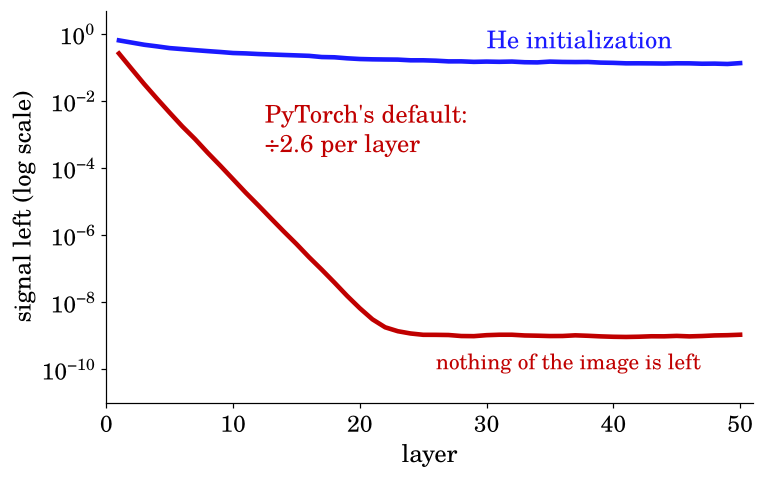

In [5]:
Ximg = Xtr[:512].flatten(1)

def signal_through_mlp(init, L=50, width=256, seeds=range(5)):
    curves = []
    for s in seeds:
        torch.manual_seed(s)
        layers = [nn.Linear(784, width)] + [nn.Linear(width, width) for _ in range(L - 1)]
        if init == 'he':
            for l in layers:
                nn.init.kaiming_normal_(l.weight, nonlinearity='relu'); nn.init.zeros_(l.bias)
        h, c = Ximg, []
        with torch.no_grad():
            for l in layers:
                h = torch.relu(l(h)); c.append(h.std(0).mean().item())
        curves.append(c)
    return np.exp(np.log(np.array(curves) + 1e-30).mean(0))       # geometric mean over 5 seeds

sig = {init: signal_through_mlp(init) for init in ('default', 'he')}
R['init_signal'] = {k: v.tolist() for k, v in sig.items()}
for k, v in sig.items():
    print(f'{k:8s} layer 1: {v[0]:.2g}   layer 10: {v[9]:.2g}   layer 20: {v[19]:.2g}   layer 50: {v[49]:.2g}')

shrink = (sig['default'][0] / sig['default'][9]) ** (1 / 9)        # average shrink per layer, layers 1-10
R['init_shrink_per_layer'] = shrink
print(f'default init: the signal shrinks about {shrink:.1f}x per layer')
fig, ax = plt.subplots(figsize=(7.2, 4.6))
x = np.arange(1, 51)
l1, = ax.semilogy(x, sig['default'], color=RED, lw=3)
t1 = ax.text(12.5, 3e-4, f"PyTorch's default:\n÷{shrink:.1f} per layer", color=RED, fontsize=16)
t1b = ax.text(26, 1e-10, 'nothing of the image is left', color=RED, fontsize=14)
t1 = [t1, t1b]
l2, = ax.semilogy(x, sig['he'], color=BLUE, lw=3)
t2 = ax.text(30, sig['he'][29] * 2.5, 'He initialization', color=BLUE, fontsize=16)
ax.set_xlabel('layer'); ax.set_ylabel('signal left (log scale)')
ax.set_ylim(1e-11, 5); ax.set_xlim(0, 51)
fig.tight_layout()
save_layers(fig, 'fig_init_signal', [[l1, *t1], [l2, t2]])
plt.show()

## Part 3 · Gradient flow at the start of training (56-layer CNNs)

One backward pass on one minibatch of 256 images, before any training. For every 3×3 convolution we record the size of its gradient (root mean square), averaged (geometric mean) over 3 random initializations.

plain, default init              first conv 1e-30   last conv 8.9e-05   ratio first/last 1.12e-26
plain, He init + batch norm      first conv 4.7   last conv 0.0017   ratio first/last 2.71e+03
residual, He init + batch norm   first conv 0.058   last conv 0.0025   ratio first/last 23


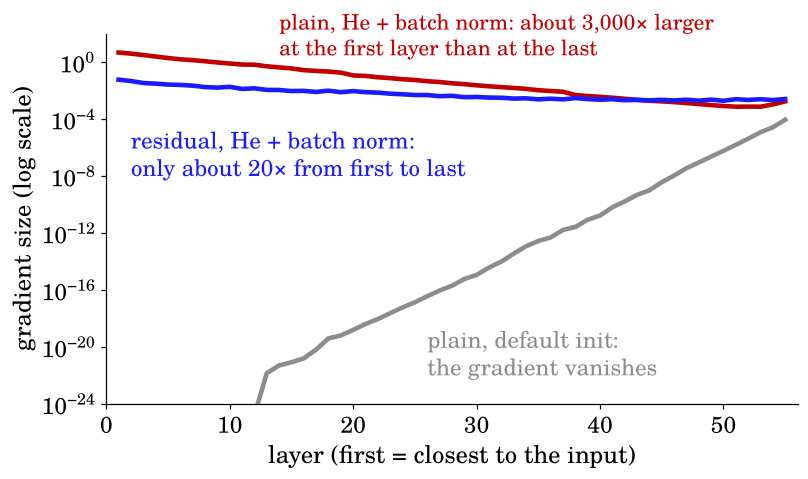

In [6]:
Xb, yb = Xtr[:256], ytr[:256]

def grad_profile(residual, bn, init, n=9, width=8, seeds=range(3)):
    G = []
    for s in seeds:
        torch.manual_seed(s)
        m = Net(n, width, residual=residual, bn=bn, init=init); m.train()
        F.cross_entropy(m(Xb), yb).backward()
        convs = [c for c in m.modules() if isinstance(c, nn.Conv2d) and c.kernel_size == (3, 3)]
        G.append([c.weight.grad.pow(2).mean().sqrt().item() for c in convs])
    G = np.array(G)
    return np.exp(np.log(np.maximum(G, 1e-30)).mean(0))

flows = {'plain, default init': grad_profile(False, False, 'default'),
         'plain, He init + batch norm': grad_profile(False, True, 'he'),
         'residual, He init + batch norm': grad_profile(True, True, 'he')}
R['grad_flow'] = {k: v.tolist() for k, v in flows.items()}
for k, v in flows.items():
    print(f'{k:32s} first conv {v[0]:.2g}   last conv {v[-1]:.2g}   ratio first/last {v[0]/v[-1]:.3g}')

fig, ax = plt.subplots(figsize=(7.6, 4.6))
x = np.arange(1, len(flows['plain, default init']) + 1)
arts = []
for (k, v), c, lbl, ypos in zip(flows.items(), [GREY, RED, BLUE],
                               ['plain, default init', 'plain, He + batch norm', 'residual, He + batch norm'],
                               [None, None, None]):
    vv = np.where(v < 1e-29, np.nan, v)
    line, = ax.semilogy(x, vv, color=c, lw=3)
    arts.append([line])
ax.set_xlabel('layer (first = closest to the input)'); ax.set_ylabel('gradient size (log scale)')
ax.set_xlim(0, len(x) + 1); ax.set_ylim(1e-24, 1e2)
def times(v):                                   # first/last ratio, rounded to 1 significant digit
    r = v[0] / v[-1]; e = 10 ** math.floor(math.log10(r)); return f'{round(r / e) * e:,.0f}'
fp, fr = flows['plain, He init + batch norm'], flows['residual, He init + batch norm']
arts[0].append(ax.text(26, 1e-22, 'plain, default init:\nthe gradient vanishes', color=GREY, fontsize=15))
arts[1].append(ax.text(14, 3, f'plain, He + batch norm: about {times(fp)}× larger\nat the first layer than at the last', color=RED, fontsize=14))
arts[2].append(ax.text(2, 1e-8, f'residual, He + batch norm:\nonly about {times(fr)}× from first to last', color=BLUE, fontsize=15))
R['grad_ratio_first_last'] = {k: v[0] / v[-1] for k, v in flows.items()}
fig.tight_layout()
save_layers(fig, 'fig_grad_flow', arts)
plt.show()

## Part 4 · The degradation problem: 20 vs 56 layers, plain vs residual

All four networks use He initialization and batch normalization and the same training recipe:
10 epochs of SGD with momentum 0.9 (one-cycle learning rate, peak 0.1), batch 128, weight decay 1e-4, on 12,000 training images.
"Training loss" is measured on 4,000 of the training images at the end of each epoch.

In [7]:
RUNS = {'plain-20': dict(n=3, residual=False), 'plain-56': dict(n=9, residual=False),
        'res-20': dict(n=3, residual=True), 'res-56': dict(n=9, residual=True)}
R.setdefault('runs', {})
models = {}
for name, cfg in RUNS.items():
    wfile = os.path.join(RESULTS, f'{name}.pt')
    torch.manual_seed(0)
    m = Net(cfg['n'], 8, residual=cfg['residual'])
    if CLASS_MODE and name in R['runs'] and os.path.exists(wfile):
        m.load_state_dict(torch.load(wfile)); print(name, 'loaded')
    else:
        print('training', name, f'({n_params(m):,} parameters)')
        R['runs'][name] = train(m); torch.save(m.state_dict(), wfile); store()
    R['runs'][name]['params'] = n_params(m)
    models[name] = m

for name, h in R['runs'].items():
    if name in RUNS:
        print(f"{name:9s} final training loss {h['train_loss'][-1]:.3f}   training acc {h['train_acc'][-1]:.1%}   "
              f"validation acc {h['val_acc'][-1]:.1%}   ({h['seconds']/60:.1f} min)")

plain-20 loaded
plain-56 loaded
res-20 loaded
res-56 loaded
plain-20  final training loss 0.155   training acc 94.6%   validation acc 88.8%   (1.8 min)
plain-56  final training loss 0.412   training acc 84.7%   validation acc 82.2%   (4.7 min)
res-20    final training loss 0.101   training acc 96.9%   validation acc 88.4%   (2.1 min)
res-56    final training loss 0.092   training acc 97.1%   validation acc 89.2%   (5.0 min)


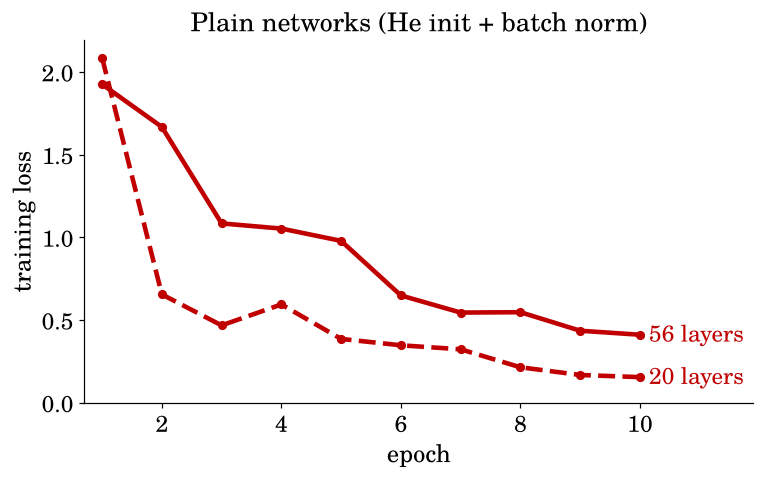

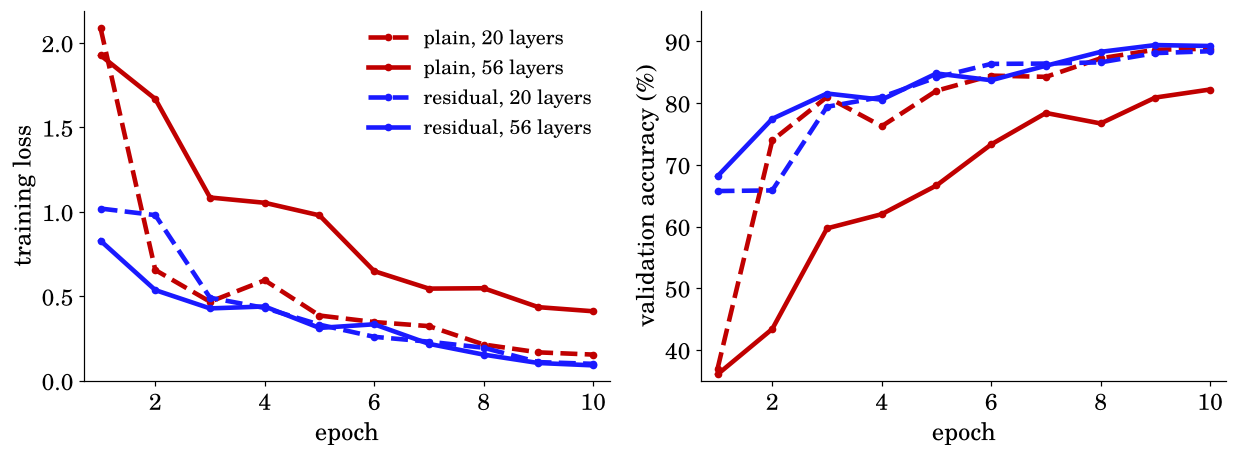

In [8]:
ep = np.arange(1, 11)
style = {'plain-20': (RED, '--'), 'plain-56': (RED, '-'), 'res-20': (BLUE, '--'), 'res-56': (BLUE, '-')}
label = {'plain-20': 'plain, 20 layers', 'plain-56': 'plain, 56 layers',
         'res-20': 'residual, 20 layers', 'res-56': 'residual, 56 layers'}

# (a) plain only: the degradation problem
fig, ax = plt.subplots(figsize=(7.2, 4.6))
arts = []
for name in ['plain-20', 'plain-56']:
    c, ls = style[name]
    l, = ax.plot(ep, R['runs'][name]['train_loss'], color=c, ls=ls, lw=3, marker='o', ms=5)
    t = ax.text(10.15, R['runs'][name]['train_loss'][-1], label[name].replace('plain, ', ''), color=c,
                va='center', fontsize=15)
    arts.append([l, t])
top = max(max(R['runs'][n]['train_loss']) for n in ['plain-20', 'plain-56'])
ax.set_xlabel('epoch'); ax.set_ylabel('training loss'); ax.set_xlim(0.7, 11.9); ax.set_ylim(0, 1.05 * top)
ax.set_title('Plain networks (He init + batch norm)', color='black')
fig.tight_layout()
save_layers(fig, 'fig_degradation', arts)
plt.show()

# (b) plain vs residual
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=False)
arts = [[], []]
for k, name in enumerate(['plain-20', 'plain-56', 'res-20', 'res-56']):
    c, ls = style[name]
    l1, = axs[0].plot(ep, R['runs'][name]['train_loss'], color=c, ls=ls, lw=3, marker='o', ms=4, label=label[name])
    l2, = axs[1].plot(ep, 100 * np.array(R['runs'][name]['val_acc']), color=c, ls=ls, lw=3, marker='o', ms=4)
    arts[0 if name.startswith('plain') else 1] += [l1, l2]
allr = [R['runs'][n] for n in ['plain-20', 'plain-56', 'res-20', 'res-56']]
axs[0].set_ylabel('training loss'); axs[0].set_ylim(0, 1.05 * max(max(h['train_loss']) for h in allr))
lo = min(min(h['val_acc']) for h in allr) * 100
axs[1].set_ylabel('validation accuracy (%)'); axs[1].set_ylim(5 * math.floor(lo / 5), 95)
for a in axs: a.set_xlabel('epoch'); a.set_xlim(0.7, 10.3)
lines = axs[0].get_lines()
leg1 = axs[0].legend(lines[:2], [label['plain-20'], label['plain-56']], loc='upper right', frameon=False, fontsize=13)
axs[0].add_artist(leg1)
leg2 = axs[0].legend(lines, [label[n] for n in ['plain-20', 'plain-56', 'res-20', 'res-56']],
                     loc='upper right', frameon=False, fontsize=13)
arts[0].append(leg1); arts[1].append(leg2)
fig.tight_layout()
# click 1: the plain runs; click 2: the residual runs join (and the legend grows)
save_layers(fig, 'fig_plain_vs_res', [arts[0], arts[1]], hide={2: [leg1]})
plt.show()

## Part 5 · Initialization and batch normalization during training (20 layers)

The same plain 20-layer network trained four ways (10 epochs each):

* no batch norm, PyTorch's default initialization, learning rate 0.003
* no batch norm, He initialization, learning rate 0.1 (the rate used in Part 4)
* no batch norm, He initialization, learning rate 0.003 (with 0.01 it never got going either)
* He initialization **with** batch norm, learning rate 0.1 (the `plain-20` run from Part 4)

plain-20 no BN, default init, lr 0.003 loaded
plain-20 no BN, He init, lr 0.1 loaded
plain-20 no BN, He init, lr 0.003 loaded
plain-20 no BN, default init, lr 0.003 validation acc after 1 epoch 10.3%, after 5 10.3%, after 10 10.3%
plain-20 no BN, He init, lr 0.1        validation acc after 1 epoch 10.1%, after 5 10.3%, after 10 10.3%
plain-20 no BN, He init, lr 0.003      validation acc after 1 epoch 10.5%, after 5 68.3%, after 10 77.7%
plain-20                               validation acc after 1 epoch 37.0%, after 5 82.0%, after 10 88.8%


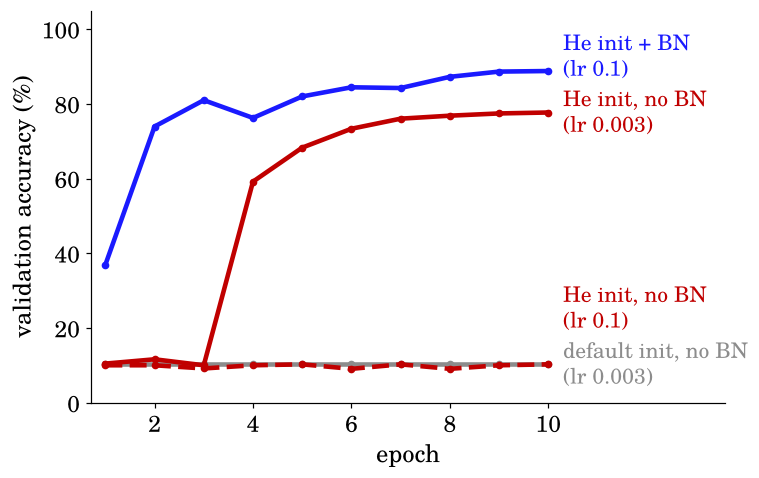

In [9]:
ABL = [('plain-20 no BN, default init, lr 0.003', 'default', 0.003),
       ('plain-20 no BN, He init, lr 0.1', 'he', 0.1),
       ('plain-20 no BN, He init, lr 0.003', 'he', 0.003)]
for name, init, lr in ABL:
    wfile = os.path.join(RESULTS, name.replace(' ', '_').replace(',', '') + '.pt')
    torch.manual_seed(0)
    m = Net(3, 8, residual=False, bn=False, init=init)
    if CLASS_MODE and name in R['runs'] and os.path.exists(wfile):
        m.load_state_dict(torch.load(wfile)); print(name, 'loaded')
    else:
        print('training', name); R['runs'][name] = train(m, lr=lr); torch.save(m.state_dict(), wfile); store()

trio = [('plain-20 no BN, default init, lr 0.003', 'default init, no BN\n(lr 0.003)', GREY, '-'),
        ('plain-20 no BN, He init, lr 0.1', 'He init, no BN\n(lr 0.1)', RED, '--'),
        ('plain-20 no BN, He init, lr 0.003', 'He init, no BN\n(lr 0.003)', RED, '-'),
        ('plain-20', 'He init + BN\n(lr 0.1)', BLUE, '-')]
for name, _, _, _ in trio:
    h = R['runs'][name]
    print(f"{name:38s} validation acc after 1 epoch {h['val_acc'][0]:.1%}, after 5 {h['val_acc'][4]:.1%}, "
          f"after 10 {h['val_acc'][-1]:.1%}")

fig, ax = plt.subplots(figsize=(7.2, 4.6))
arts = []
ends = [100 * R['runs'][n]['val_acc'][-1] for n, _, _, _ in trio]
# spread the end labels so that they do not overlap
order_ = np.argsort(ends); ypos = np.array(ends, dtype=float)
for k in range(1, len(order_)):
    a, b = order_[k - 1], order_[k]
    ypos[b] = max(ypos[b], ypos[a] + 15)
for (name, lbl, c, ls), yp in zip(trio, ypos):
    l, = ax.plot(ep, 100 * np.array(R['runs'][name]['val_acc']), color=c, ls=ls, lw=3, marker='o', ms=4)
    t = ax.text(10.3, yp, lbl, color=c, va='center', fontsize=14)
    arts.append([l, t])
ax.set_xlabel('epoch'); ax.set_ylabel('validation accuracy (%)'); ax.set_xlim(0.7, 13.6); ax.set_ylim(0, 105)
ax.set_xticks([2, 4, 6, 8, 10])
fig.tight_layout()
save_layers(fig, 'fig_init_bn_training', arts)
plt.show()

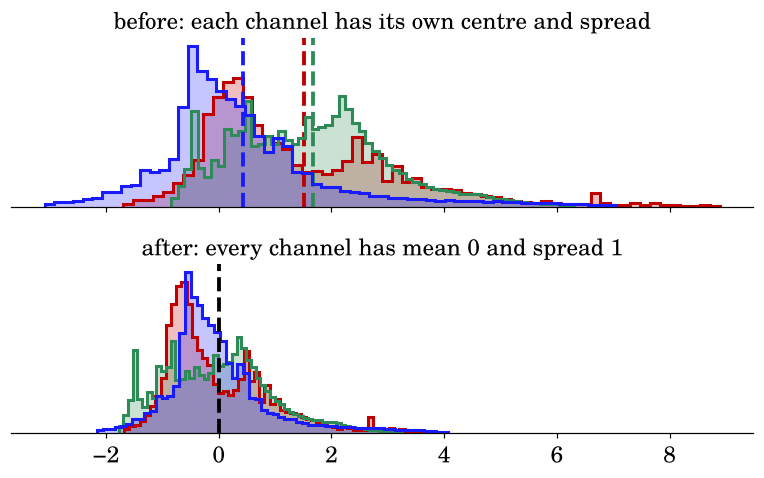

mean and std of the three channels before normalization: [(1.52, 1.92), (1.67, 1.42), (0.43, 1.63)]


In [10]:
# What batch norm does to one layer: the inputs of the 5th batch-norm layer of the trained plain-20,
# for one minibatch of 256 images, before and after normalization (before gamma and beta)
m = models['plain-20']; m.eval()
bn_layer = [b for b in m.modules() if isinstance(b, nn.BatchNorm2d)][4]
cap = {}
hk = bn_layer.register_forward_hook(lambda mod, inp, out: cap.__setitem__('x', inp[0].detach()))
with torch.no_grad(): m.train(); m(Xtr[:256]); m.eval()
hk.remove()
x = cap['x']                                    # (256, C, H, W)
chans = [0, 3, 6]
fig, axs = plt.subplots(2, 1, figsize=(7.2, 4.6), sharex=True)
cols = [RED, GREEN, BLUE]
stats = []
for c, col in zip(chans, cols):
    v = x[:, c].flatten().numpy()
    mu, sd = v.mean(), v.std()
    stats.append((float(mu), float(sd)))
    lo, hi = np.percentile(v, [0.5, 99.5])
    v = v[(v >= lo) & (v <= hi)]
    for a, data in ((axs[0], v), (axs[1], (v - mu) / sd)):
        a.hist(data, bins=60, color=col, alpha=0.25, density=True)
        a.hist(data, bins=60, color=col, histtype='step', lw=2, density=True)
    axs[0].axvline(mu, color=col, lw=2.5, ls='--')            # this channel's own centre
axs[0].set_title('before: each channel has its own centre and spread', fontsize=15)
axs[1].set_title('after: every channel has mean 0 and spread 1', fontsize=15)
for a in axs:
    a.set_yticks([]); a.spines['left'].set_visible(False)
axs[1].axvline(0, color='black', lw=2.5, ls='--')
fig.tight_layout()
save(fig, 'fig_bn_histograms')
R['bn_channel_stats'] = stats
plt.show()
print('mean and std of the three channels before normalization:', [(round(a, 2), round(b, 2)) for a, b in stats])

## Part 6 · Remove one block

Take the trained 56-layer networks and delete one block at a time (27 blocks).
In the residual network a deleted block keeps only its shortcut; in the plain network the signal skips the block.
(The first block of stages 2 and 3 changes the shape, so it cannot be deleted from the plain network.)

plain-56: full 82.2%   one block removed: median 11.3%, worst 3.5%, best 49.4%


res-56: full 89.2%   one block removed: median 87.2%, worst 10.4%, best 89.4%


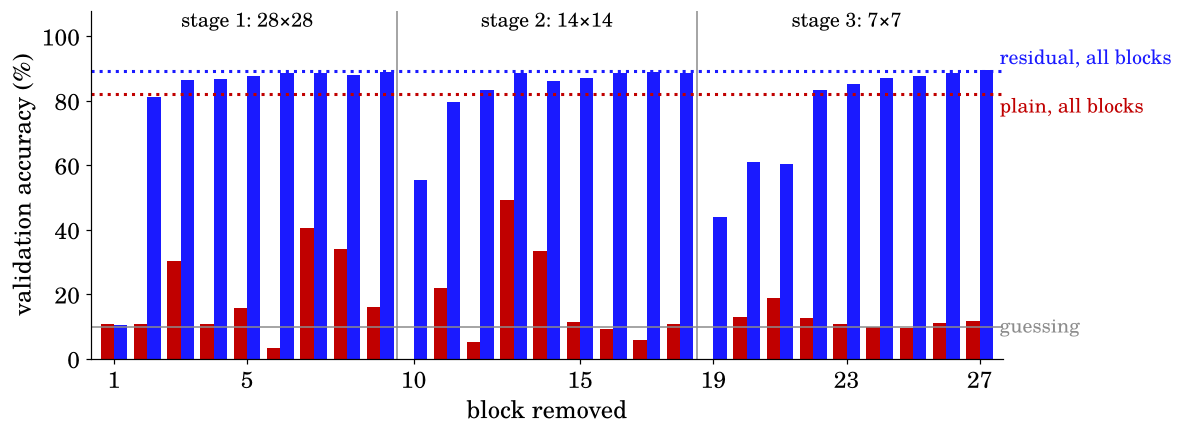

In [11]:
def knockout(m):
    accs = []
    for b in m.blocks:
        if not b.residual and (b.conv1.stride != (1, 1) or b.conv1.in_channels != b.conv2.out_channels):
            accs.append(None); continue
        b.removed = True
        accs.append(evaluate(m, Xva, yva)[1])
        b.removed = False
    return accs

ko = {}
for name in ['plain-56', 'res-56']:
    full = evaluate(models[name], Xva, yva)[1]
    ko[name] = {'full': full, 'removed': knockout(models[name])}
    r = [a for a in ko[name]['removed'] if a is not None]
    print(f'{name}: full {full:.1%}   one block removed: median {np.median(r):.1%}, worst {min(r):.1%}, best {max(r):.1%}')
R['knockout'] = ko

fig, ax = plt.subplots(figsize=(11, 4.2))
idx = np.arange(1, 28)
pr = [np.nan if a is None else 100 * a for a in ko['plain-56']['removed']]
rr = [100 * a for a in ko['res-56']['removed']]
b1 = ax.bar(idx - 0.2, pr, width=0.4, color=RED)
b2 = ax.bar(idx + 0.2, rr, width=0.4, color=BLUE)
h1 = ax.axhline(100 * ko['plain-56']['full'], color=RED, ls=':', lw=2)
h2 = ax.axhline(100 * ko['res-56']['full'], color=BLUE, ls=':', lw=2)
ax.axhline(10, color=GREY, lw=1)
t0 = ax.text(27.6, 10, 'guessing', color=GREY, va='center', fontsize=13)
t1 = ax.text(27.6, 100 * ko['plain-56']['full'] - 4, 'plain, all blocks', color=RED, va='center', fontsize=13)
t2 = ax.text(27.6, 100 * ko['res-56']['full'] + 4, 'residual, all blocks', color=BLUE, va='center', fontsize=13)
ax.set_xlabel('block removed'); ax.set_ylabel('validation accuracy (%)')
ax.set_xlim(0.3, 27.7); ax.set_ylim(0, 108); ax.set_yticks([0, 20, 40, 60, 80, 100]); ax.set_xticks([1, 5, 10, 15, 19, 23, 27])
for xs in (9.5, 18.5):
    ax.axvline(xs, color=GREY, lw=1, ls='-')
for xc, lbl in ((5, 'stage 1: 28×28'), (14, 'stage 2: 14×14'), (23, 'stage 3: 7×7')):
    ax.text(xc, 103, lbl, ha='center', fontsize=13, color='black')
fig.tight_layout()
save_layers(fig, 'fig_knockout', [[*b1, h1, t1, t0], [*b2, h2, t2]])
plt.show()

## Part 7 · Inspecting a pretrained ResNet-18

`torchvision` ships ResNet-18 trained on ImageNet (1.28 million images, 1000 classes). We look at its structure, trace the shape of one image through it, and ask it about four public-domain photos that come with scikit-image (`pip install scikit-image`).

In [12]:
import torchvision
from torchvision.models import resnet18, ResNet18_Weights
try:
    import skimage.data as skd
    from PIL import Image
    photos = {'cat': Image.fromarray(skd.chelsea()), 'coffee': Image.fromarray(skd.coffee()),
              'astronaut': Image.fromarray(skd.astronaut()), 'rocket': Image.fromarray(skd.rocket())}
except ImportError:
    photos = None

try:
    w = ResNet18_Weights.IMAGENET1K_V1
    r18 = resnet18(weights=w).eval()
    live = True
except Exception as e:                      # no internet: architecture only, saved predictions
    print('could not download the weights:', e)
    r18, live = resnet18().eval(), False

print(f'{n_params(r18):,} parameters')
print(r18.layer2[0])                         # one block where the shape changes: note the 1x1 'downsample'

shapes = []
x = torch.zeros(1, 3, 224, 224)
with torch.no_grad():
    shapes.append(('input', tuple(x.shape[1:])))
    x = r18.relu(r18.bn1(r18.conv1(x))); shapes.append(('7x7 conv, stride 2', tuple(x.shape[1:])))
    x = r18.maxpool(x); shapes.append(('max pool', tuple(x.shape[1:])))
    for k in range(1, 5):
        x = getattr(r18, f'layer{k}')(x); shapes.append((f'layer{k} (2 blocks)', tuple(x.shape[1:])))
    x = torch.flatten(r18.avgpool(x), 1); shapes.append(('average pool', tuple(x.shape[1:])))
    x = r18.fc(x); shapes.append(('fully connected', tuple(x.shape[1:])))
for s in shapes: print(f'{s[0]:22s} {s[1]}')
R['resnet18_shapes'] = shapes
R['resnet18_params'] = n_params(r18)

if live and photos is not None:
    tf = w.transforms()
    with torch.no_grad():
        P = r18(torch.stack([tf(im) for im in photos.values()])).softmax(1)
    preds = {}
    for name, p in zip(photos, P):
        v, i = p.topk(3)
        preds[name] = [(w.meta['categories'][j], float(a)) for a, j in zip(v, i)]
    R['resnet18_predictions'] = preds
store()
for name, top in R.get('resnet18_predictions', {}).items():
    print(f'{name:10s}', '  '.join(f'{c} {p:.0%}' for c, p in top))

11,689,512 parameters
BasicBlock(
  (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (downsample): Sequential(
    (0): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
)
input                  (3, 224, 224)
7x7 conv, stride 2     (64, 112, 112)
max pool               (64, 56, 56)
layer1 (2 blocks)      (64, 56, 56)
layer2 (2 blocks)      (128, 28, 28)
layer3 (2 blocks)      (256, 14, 14)
layer4 (2 blocks)      (512, 7, 7)
average pool           (512,)
fully connected        (1000,)
cat        Egyptian cat 39%  t

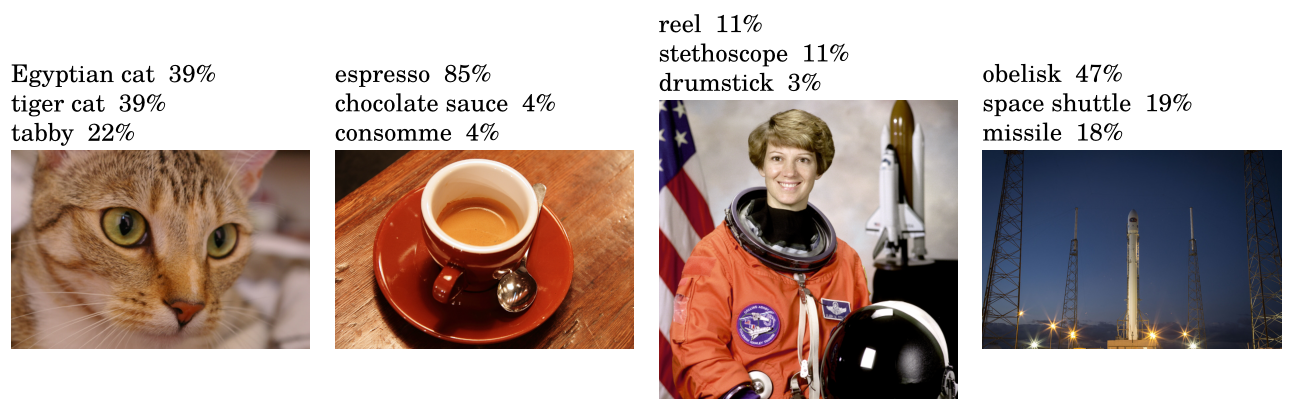

In [13]:
if photos is not None and 'resnet18_predictions' in R:
    fig, axs = plt.subplots(1, 4, figsize=(12, 4.6))
    for ax, (name, im) in zip(axs, photos.items()):
        ax.imshow(im); ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        top = R['resnet18_predictions'][name]
        txt = '\n'.join(f'{c}  {p:.0%}' for c, p in top)
        ax.set_title(txt, fontsize=16, loc='left', color='black')
    fig.tight_layout()
    save(fig, 'fig_resnet18_predictions')
    plt.show()

## Things to try (with or without an AI assistant)

1. Change `width=8` to `width=16` in Part 4. Does the 56-layer plain network catch up?
2. Remove batch norm from the residual network (`bn=False`). What happens to the size of the signal after 27 blocks? (Hint: each block *adds* its output to its input.)
3. torchvision's ResNet has an option `zero_init_residual=True` that sets the last batch-norm scale γ of every block to 0. What does every block compute at the start of training? Why could that help?
4. In Part 7, find a photo of something that is **not** one of the 1000 ImageNet classes. What does the network say, and how confident is it?